# Fine-tuning Whisper for Automatic Speech Recognition

In [ ]:
!pip install torch torchaudio transformers datasets jiwer librosa soundfile evaluate accelerate huggingface_hub matplotlib seaborn pandas numpy tqdm -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 62.3 MB/s eta 0:00:00


In [ ]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass
from typing import Dict, Any
from tqdm.auto import tqdm
import re
from typing import List
import torch
import librosa

from datasets import (
    load_dataset,
    DatasetDict,
    Audio,
)
from transformers import (
    WhisperFeatureExtractor,
    WhisperTokenizer,
    WhisperProcessor,
    WhisperForConditionalGeneration,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer,
    EarlyStoppingCallback,
)
import evaluate
from jiwer import wer, transforms as jiwer_transforms

## 1. Configuration




In [ ]:
config = {
    "dataset_name":"openslr/librispeech_asr",
    "train_split": "train.clean.100",
    "dev_split":"validation.clean",
    "test_split":"test.clean",
    "streaming":True,
    "max_train_samples":5000,
    "max_eval_samples":500,
    "max_test_samples":500,

    "sample_rate":16000,
    "max_audio_len_sec":30,

    "n_mfcc":13,
    "n_fft":512,
    "hop_length":160,
    "win_length":400,
    "n_mels":80,
    "frame_context":3,

    "model_name":"openai/whisper-small",
    "language":"en",
    "task":"transcribe",

    "output_dir":"./whisper-librispeech-clean",
    "num_train_epochs":3,
    "per_device_train_batch_size":8,
    "per_device_eval_batch_size":8,
    "gradient_accumulation_steps":2,
    "learning_rate":1e-5,
    "warmup_steps":500,
    "max_steps":4000,
    "fp16":True,
    "evaluation_strategy": "steps",
    "eval_steps":200,
    "save_steps":200,
    "logging_steps":25,
    "load_best_model_at_end":True,
    "metric_for_best_model":"wer",
    "greater_is_better":False,
    "seed":42,
}

In [ ]:
random.seed(config["seed"])
np.random.seed(config["seed"])
torch.manual_seed(config["seed"])

device = "cuda" if torch.cuda.is_available() else "cpu"
config["fp16"] = config["fp16"] and (device == "cuda")

## 2. Dataset Loading and Exploration




In [ ]:
raw_datasets = DatasetDict()

raw_datasets["train"] = load_dataset(
    config["dataset_name"],
    "clean",
    split="train.100",
    streaming=config["streaming"],
    trust_remote_code=True,
)

raw_datasets["dev"] = load_dataset(
    config["dataset_name"],
    "clean",
    split="validation",
    streaming=config["streaming"],
    trust_remote_code=True,
)

raw_datasets["test"] = load_dataset(
    config["dataset_name"],
    "clean",
    split="test",
    streaming=config["streaming"],
    trust_remote_code=True,
)

for split in raw_datasets:
    raw_datasets[split] = raw_datasets[split].cast_column(
        "audio",
        Audio(sampling_rate=config["sample_rate"])
    )

sample = next(iter(raw_datasets["train"]))
print(f"\nSample fields:{list(sample.keys())}")
print(f"Speaker ID:{sample['speaker_id']}")
print(f"Chapter ID:{sample['chapter_id']}")
print(f"Text:{sample['text'][:80]}")
print(f"Audio SR:{sample['audio']['sampling_rate']}")
print(f"Audio len:{len(sample['audio']['array']) / sample['audio']['sampling_rate']:.2f} seconds")

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'openslr/librispeech_asr' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'openslr/librispeech_asr' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be 

README.md: 0.00B [00:00, ?B/s]

Resolving data files:   0%|          | 0/48 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/48 [00:00<?, ?it/s]

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'openslr/librispeech_asr' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'openslr/librispeech_asr' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


Resolving data files:   0%|          | 0/48 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/48 [00:00<?, ?it/s]

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'openslr/librispeech_asr' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'openslr/librispeech_asr' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


Resolving data files:   0%|          | 0/48 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/48 [00:00<?, ?it/s]


Sample fields:['file', 'audio', 'text', 'speaker_id', 'chapter_id', 'id']
Speaker ID:374
Chapter ID:180298
Text:CHAPTER SIXTEEN I MIGHT HAVE TOLD YOU OF THE BEGINNING OF THIS LIAISON IN A FEW 
Audio SR:16000
Audio len:14.53 seconds


In [ ]:


eda_data = []
for i, sample in enumerate(raw_datasets["train"]):
    if i >= 300:
        break
    audio_array = sample["audio"]["array"]
    duration = len(audio_array) / config["sample_rate"]
    eda_data.append({
        "speaker_id":sample["speaker_id"],
        "chapter_id":sample["chapter_id"],
        "text":sample["text"],
        "duration_s":duration,
        "num_words":len(sample["text"].split()),
        "num_chars":len(sample["text"]),
    })

df_eda = pd.DataFrame(eda_data)

In [ ]:
print("Duration Statistics (seconds):")
print(df_eda["duration_s"].describe().to_string())
print(f"\nUnique speakers in sample: {df_eda['speaker_id'].nunique()}")
print(f"Avg words per utterance:{df_eda['num_words'].mean():.1f}")
print(f"Avg chars per utterance:{df_eda['num_chars'].mean():.1f}")

Duration Statistics (seconds):
count    300.000000
mean      13.449134
std        2.981800
min        2.785000
25%       12.896250
50%       14.392500
75%       15.187500
max       17.210000

Unique speakers in sample: 3
Avg words per utterance:39.1
Avg chars per utterance:201.5


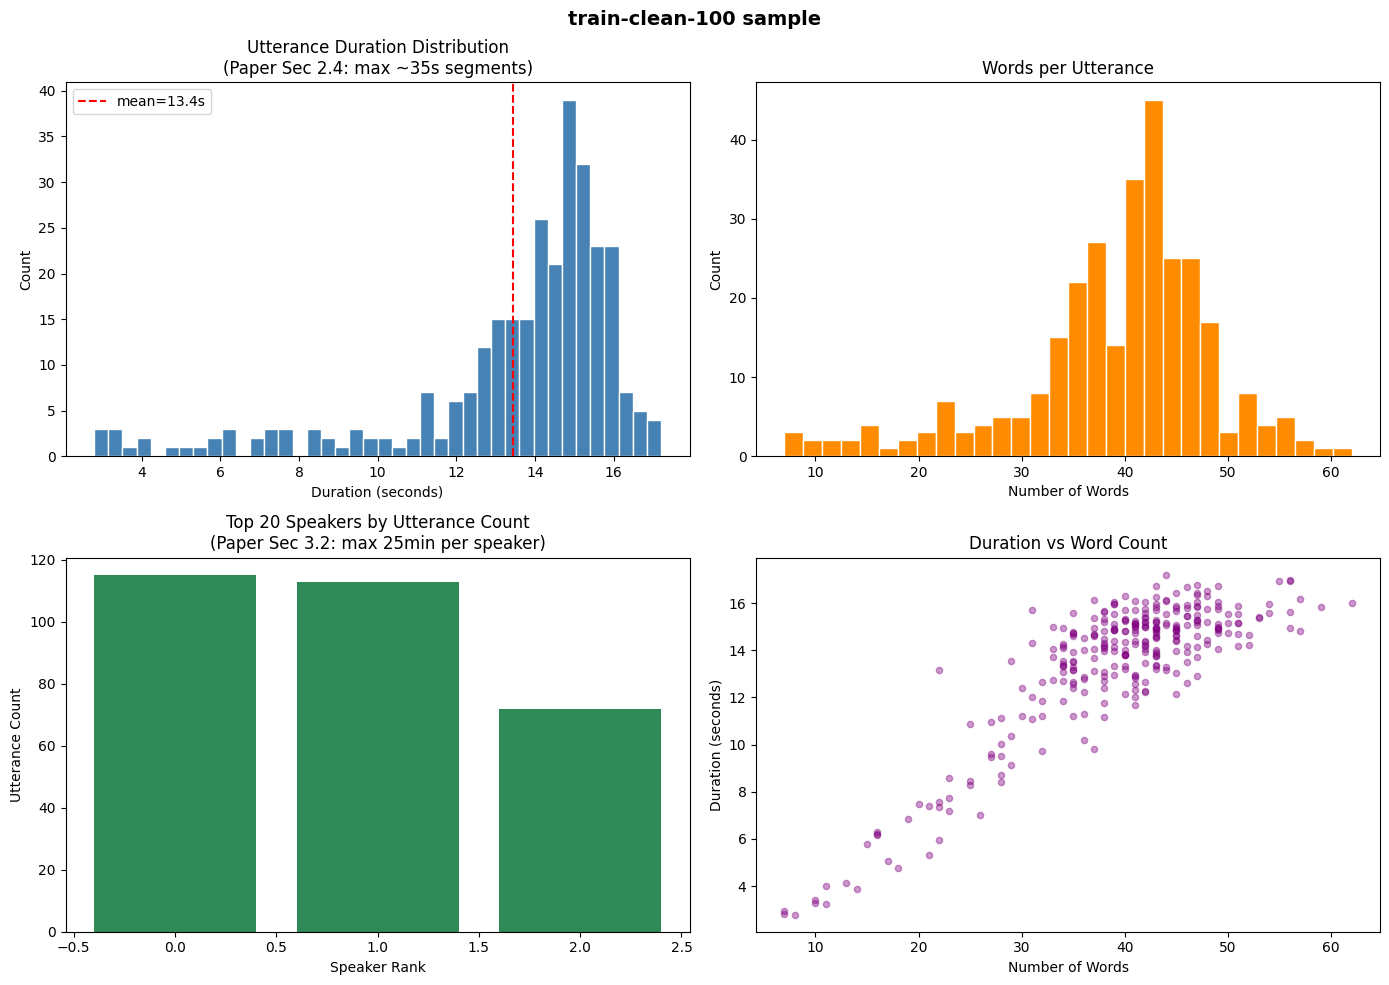

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("train-clean-100 sample", fontsize=14, fontweight="bold")

# Plot 1: Duration distribution
# Paper Section 2.4: segments split at silence ≥ 0.3s
axes[0, 0].hist(df_eda["duration_s"], bins=40, color="steelblue", edgecolor="white")
axes[0, 0].set_title("Utterance Duration Distribution\n(Paper Sec 2.4: max ~35s segments)")
axes[0, 0].set_xlabel("Duration (seconds)")
axes[0, 0].set_ylabel("Count")
axes[0, 0].axvline(df_eda["duration_s"].mean(), color="red", linestyle="--", label=f'mean={df_eda["duration_s"].mean():.1f}s')
axes[0, 0].legend()

# Plot 2: Words per utterance
axes[0, 1].hist(df_eda["num_words"], bins=30, color="darkorange", edgecolor="white")
axes[0, 1].set_title("Words per Utterance")
axes[0, 1].set_xlabel("Number of Words")
axes[0, 1].set_ylabel("Count")

# Plot 3: Top 20 speakers by utterance count
speaker_counts = df_eda["speaker_id"].value_counts().head(20)
axes[1, 0].bar(range(len(speaker_counts)), speaker_counts.values, color="seagreen")
axes[1, 0].set_title("Top 20 Speakers by Utterance Count\n(Paper Sec 3.2: max 25min per speaker)")
axes[1, 0].set_xlabel("Speaker Rank")
axes[1, 0].set_ylabel("Utterance Count")

# Plot 4: Duration vs Word Count scatter
axes[1, 1].scatter(df_eda["num_words"], df_eda["duration_s"], alpha=0.4, color="purple", s=20)
axes[1, 1].set_title("Duration vs Word Count")
axes[1, 1].set_xlabel("Number of Words")
axes[1, 1].set_ylabel("Duration (seconds)")

plt.tight_layout()
plt.savefig("eda_plots.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
sample = next(iter(raw_datasets["dev"]))
audio_array = np.array(sample["audio"]["array"], dtype=np.float32)
sr = config["sample_rate"]

mfcc = librosa.feature.mfcc(
    y=audio_array,
    sr=sr,
    n_mfcc=config["n_mfcc"],
    n_fft=config["n_fft"],
    hop_length=config["hop_length"],
    win_length=config["win_length"],
)

mfcc_delta  = librosa.feature.delta(mfcc)
mfcc_delta2 = librosa.feature.delta(mfcc, order=2)
mfcc_full   = np.concatenate([mfcc, mfcc_delta, mfcc_delta2], axis=0)

def frame_splice(features: np.ndarray, context: int = 3) -> np.ndarray:

    D, T = features.shape
    spliced = []
    padded = np.pad(features, ((0, 0), (context, context)), mode="edge")
    for t in range(T):
        window = padded[:, t:t + 2 * context + 1].reshape(-1)
        spliced.append(window)
    return np.array(spliced).T

mfcc_spliced = frame_splice(mfcc_full, context=config["frame_context"])
print(f"\nMFCC shape (13 coeff):{mfcc.shape}")
print(f"MFCC + delta + delta2 shape:{mfcc_full.shape}")
print(f"After frame-splice (±3 frames):{mfcc_spliced.shape}")

mel_spec = librosa.feature.melspectrogram(
    y=audio_array,
    sr=sr,
    n_mels=config["n_mels"],
    n_fft=config["n_fft"],
    hop_length=config["hop_length"],
)
log_mel = librosa.power_to_db(mel_spec, ref=np.max)


MFCC shape (13 coeff):(13, 660)
MFCC + delta + delta2 shape:(39, 660)
After frame-splice (±3 frames):(273, 660)


## 3. Feature Extraction and Tokenization



In [ ]:
feature_extractor = WhisperFeatureExtractor.from_pretrained(
    config["model_name"]
)


tokenizer = WhisperTokenizer.from_pretrained(
    config["model_name"],
    language=config["language"],
    task=config["task"]
)

processor = WhisperProcessor.from_pretrained(
    config["model_name"],
    language=config["language"],
    task=config["task"]
)

model = WhisperForConditionalGeneration.from_pretrained(
    config["model_name"]
)

model.generation_config.language = config["language"]
model.generation_config.task = config["task"]
model.generation_config.forced_decoder_ids = None


model = model.to(device)

preprocessor_config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

normalizer.json: 0.00B [00:00, ?B/s]

... (2 outputs left out)

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/967M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

generation_config.json: 0.00B [00:00, ?B/s]

In [ ]:
ABBREVIATION_MAP = {
    "mr.": "mister",
    "mrs.": "missus",
    "dr.": "doctor",
    "prof.": "professor",
    "st.": "saint",
    "jr.": "junior",
    "sr.": "senior",
    "vs.": "versus",
    "etc.": "et cetera",
}


def normalize_text_paper(text: str) -> str:
    text = text.lower().strip()

    for abbr, expansion in ABBREVIATION_MAP.items():
        text = text.replace(abbr, expansion)

    text = re.sub(r"[^\w\s']", " ", text)

    text = re.sub(r"\s+", " ", text).strip()

    return text


wer_transform = jiwer_transforms.Compose([
    jiwer_transforms.ToLowerCase(),
    jiwer_transforms.RemovePunctuation(),
    jiwer_transforms.RemoveMultipleSpaces(),
    jiwer_transforms.Strip(),
    jiwer_transforms.RemoveEmptyStrings(),
    jiwer_transforms.ReduceToListOfListOfWords(),
])


def compute_wer(references: List[str], hypotheses: List[str]) -> float:
    return wer(
        references,
        hypotheses,
        reference_transform=wer_transform,
        hypothesis_transform=wer_transform,
    )

In [ ]:
test = "Mr. Smith and Dr. Jones discussed the matter vs. the proposal."

afterPreprocessing = normalize_text_paper(test)
print(f"Original:{test}")
print(f"Normalized:{afterPreprocessing}")

Original:Mr. Smith and Dr. Jones discussed the matter vs. the proposal.
Normalized:mister smith and doctor jones discussed the matter versus the proposal


In [ ]:
MAX_AUDIO_LEN = config["sample_rate"] * config["max_audio_len_sec"]

def preprocess_sample(sample: Dict[str, Any]) -> Dict[str, Any]:
    audio_array = sample["audio"]["array"]

    if len(audio_array) > MAX_AUDIO_LEN:
        audio_array = audio_array[:MAX_AUDIO_LEN]

    input_features = feature_extractor(
        audio_array,
        sampling_rate=config["sample_rate"],
        return_tensors="pt"
    ).input_features[0]

    text = normalize_text_paper(sample["text"])

    labels = tokenizer(text).input_ids

    return {
        "input_features": input_features,
        "labels": labels,
        "input_length": len(audio_array) / config["sample_rate"],
    }

In [ ]:
train_dataset = raw_datasets["train"].take(config["max_train_samples"])
dev_dataset = raw_datasets["dev"].take(config["max_eval_samples"])
test_dataset = raw_datasets["test"].take(config["max_test_samples"])

In [ ]:
train_dataset = train_dataset.map(
    preprocess_sample,
    remove_columns=list(next(iter(raw_datasets["train"])).keys())
)
dev_dataset = dev_dataset.map(
    preprocess_sample,
    remove_columns=list(next(iter(raw_datasets["dev"])).keys())
)
test_dataset = test_dataset.map(
    preprocess_sample,
    remove_columns=list(next(iter(raw_datasets["test"])).keys())
)

In [ ]:
sample_processed = next(iter(train_dataset))

print(f"input_features shape:{np.array(sample_processed['input_features']).shape}")
print(f"labels (first 10):{sample_processed['labels'][:10]}")
print(f"labels decoded:{tokenizer.decode(sample_processed['labels'], skip_special_tokens=True)[:60]}")

input_features shape:(80, 3000)
labels (first 10):[50258, 50259, 50359, 50363, 339, 5446, 27847, 741, 1062, 362]
labels decoded:chapter sixteen i might have told you of the beginning of th


## 4. Data Collator



In [ ]:
@dataclass
class DataCollatorSpeechSeq2SeqWithPadding:
    processor:  Any
    decoder_start_token_id: int

    def __call__(self, features: List[Dict[str, Any]]) -> Dict[str, torch.Tensor]:
        input_features = [
            {"input_features": feature["input_features"]}
            for feature in features
        ]
        batch = self.processor.feature_extractor.pad(
            input_features,
            return_tensors="pt"
        )

        label_features = [
            {"input_ids": feature["labels"]}
            for feature in features
        ]
        labels_batch = self.processor.tokenizer.pad(
            label_features,
            return_tensors="pt"
        )

        labels = labels_batch["input_ids"].masked_fill(
            labels_batch.attention_mask.ne(1), -100
        )

        bos_id = self.decoder_start_token_id
        if (labels[:, 0] == bos_id).all().item():
            labels = labels[:, 1:]

        batch["labels"] = labels
        return batch

In [ ]:
data_collator = DataCollatorSpeechSeq2SeqWithPadding(
    processor=processor,
    decoder_start_token_id=model.config.decoder_start_token_id,
)

## 5. Model Training



In [ ]:
wer_metric = evaluate.load("wer")


def compute_metrics(pred) -> Dict[str, float]:
    pred_ids = pred.predictions
    label_ids = pred.label_ids

    label_ids[label_ids == -100] = tokenizer.pad_token_id

    pred_str  = tokenizer.batch_decode(pred_ids,  skip_special_tokens=True)
    label_str = tokenizer.batch_decode(label_ids, skip_special_tokens=True)

    pred_str  = [normalize_text_paper(p) for p in pred_str]
    label_str = [normalize_text_paper(l) for l in label_str]

    wer_score = 100 * wer_metric.compute(
        predictions=pred_str,
        references=label_str
    )

    return {"wer": wer_score}

In [ ]:

training_args = Seq2SeqTrainingArguments(
    output_dir=config["output_dir"],

    num_train_epochs=config["num_train_epochs"],
    max_steps=config["max_steps"],
    warmup_steps=config["warmup_steps"],

    per_device_train_batch_size=config["per_device_train_batch_size"],
    per_device_eval_batch_size=config["per_device_eval_batch_size"],
    gradient_accumulation_steps=config["gradient_accumulation_steps"],

    learning_rate=config["learning_rate"],
    weight_decay=0.0,

    fp16=config["fp16"],
    bf16=False,


    eval_strategy=config["evaluation_strategy"],
    eval_steps=config["eval_steps"],

    save_strategy=config["evaluation_strategy"],
    save_steps=config["save_steps"],
    save_total_limit=3,

    load_best_model_at_end=config["load_best_model_at_end"],
    metric_for_best_model=config["metric_for_best_model"],
    greater_is_better=config["greater_is_better"],

    predict_with_generate=True,
    generation_max_length=225,

    logging_steps=config["logging_steps"],
    logging_dir=f"{config['output_dir']}/logs",
    report_to="none",

    dataloader_num_workers=0,
    remove_unused_columns=False,
    label_names=["labels"],
    seed=config["seed"],
    push_to_hub=False,
)

`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


In [ ]:
early_stopping_callback = EarlyStoppingCallback(
    early_stopping_patience=3,
    early_stopping_threshold=0.001,
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=dev_dataset,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[early_stopping_callback],
)

In [ ]:
train_result = trainer.train()

Step,Training Loss,Validation Loss,Wer
200,0.143165,0.118517,3.859096
400,0.130114,0.118760,4.016824
600,0.081840,0.125366,4.079916


The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
A custom logits processor of type <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> has been passed to `.generate()`, but it was also created in `.generate()`, given its parameterization. The custom <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> will take precedence. Please check the docstring of <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> to see related `.generate()` flags.
A custom logits processor of type <class 'transformers.generation.logits_process.SuppressTokensAtBeginLogitsProcessor'> has been passed to `.generate()`, but it was also created in `.generate()`, given its parameterization. The custom <class 'transformers.generation.logits_process.SuppressTokensA

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Step,Training Loss,Validation Loss,Wer
200,0.143165,0.118517,3.859096
400,0.130114,0.118760,4.016824
600,0.081840,0.125366,4.079916
800,0.024737,0.131600,3.817035
1000,0.114730,0.140672,4.332282
1200,0.016567,0.140477,3.848580
1400,0.005874,0.145174,3.848580


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['proj_out.weight'].


In [ ]:
trainer.save_model()
processor.save_pretrained(config["output_dir"])

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

['./whisper-librispeech-clean/processor_config.json']

## 6. Evaluation



In [ ]:
all_predictions = []
all_references  = []
all_durations   = []

model.eval()
with torch.no_grad():
    for i, sample in enumerate(tqdm(test_dataset, desc="Evaluating")):
        input_features = torch.tensor(
            sample["input_features"]
        ).unsqueeze(0).to(device)

        predicted_ids = model.generate(
            input_features,
            language=config["language"],
            task=config["task"],
            num_beams=5,
            max_new_tokens=225,
        )

        prediction = tokenizer.batch_decode(
            predicted_ids, skip_special_tokens=True
        )[0]
        reference = tokenizer.batch_decode(
            [sample["labels"]], skip_special_tokens=True
        )[0]

        prediction = normalize_text_paper(prediction)
        reference  = normalize_text_paper(reference)

        all_predictions.append(prediction)
        all_references.append(reference)
        all_durations.append(sample.get("input_length", 0))

final_wer = 100 * wer_metric.compute(
    predictions=all_predictions,
    references=all_references,
)
final_cer = 100 * evaluate.load("cer").compute(
    predictions=all_predictions,
    references=all_references,
)


Evaluating: 0it [00:00, ?it/s]

/tmp/ipykernel_1983/2360101863.py:23: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  input_features = torch.tensor(
Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
/tmp/ipykernel_1983/2360101863.py:23: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  input_features = torch.tensor(
Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main

In [ ]:
print(f"WER (Word Error Rate):{final_wer:.2f}%")
print(f"CER (Char Error Rate):{final_cer:.2f}%")
print(f"Total utterances:{len(all_predictions)}")

WER (Word Error Rate):3.99%
CER (Char Error Rate):1.42%
Total utterances:500


The final WER and CER indicate the overall performance of the fine-tuned Whisper model on the test dataset. A lower score is better.

In [ ]:
for i in range(min(5, len(all_predictions))):
    utt_wer = wer([all_references[i]], [all_predictions[i]])
    print(f"[{i+1}] REF: {all_references[i][:70]}")
    print(f"HYP: {all_predictions[i][:70]}")
    print(f"WER: {utt_wer*100:.1f}%\n")

[1] REF: concord returned to its place amidst the tents
HYP: concord returned to its place amidst the tents
WER: 0.0%

[2] REF: the english forwarded to the french baskets of flowers of which they h
HYP: the english voted to the french baskets of flowers of which they had m
WER: 2.3%

[3] REF: congratulations were poured in upon the princess everywhere during her
HYP: congratulations were poured in upon the princess everywhere during her
WER: 0.0%

[4] REF: from the respect paid her on all sides she seemed like a queen and fro
HYP: from the respect paid her on all sides she seemed like a queen and fro
WER: 0.0%

[5] REF: she taught her daughter then by her own affection for it that love for
HYP: she taught her daughter then by her own affection for it that love for
WER: 3.2%



Here are a few examples showing the reference text, the model's hypothesis, and the Word Error Rate for each utterance.

In [ ]:
print("REF:", all_references[4])
print("HYP:", all_predictions[4])

REF: she taught her daughter then by her own affection for it that love for a country where they had both been hospitably received and where a brilliant future opened before them
HYP: she taught her daughter then by her own affection for it that love for a country where they had both been hospitably received and where a brilliant future opened for them
